# Лабораторная работа №5 Квантовые сумматоры. Алгоритм Гровера

In [ ]:
Цель работы: ознакомление с выполнением простого сложения с помощью квантовых схем, ознакомление с алгоритмом Гровера и его реализацией в квантовых системах.

## Задания 1-3 (теоретический материал `adder.ipynb`)

# Задание 1
Полный сумматор принимает на вход два двоичных числа плюс бит переполнения, который мы назовем X.
Создайте полный сумматор с входными данными:

$A=1$, $B=0$, $X=1$
.

Таблица истинности для полного сумматора приведена ниже.

|A(input)|B(input)|X(carry input)|S(sum)|C(carry out)|
|--|--|--|--|--|
|0|0|0|0|0|
|0|0|1|1|0|
|0|1|0|1|0|
|0|1|1|0|1|
|1|0|0|1|0|
|1|0|1|0|1|
|1|1|0|0|1|
|1|1|1|1|1|

1. Изучить теоретический материал.
2. Средствами Qiskit или используя средства интерактивной среды IBM Quantum Experience https://quantum.ibm.com/composer/ , создать:
* Полный сумматор для входов $A=1$, $B=0$, $X=1$. Получите вектор состояния (для него уберите измерения) и распределение результатов (с измерениями, `shots=1024`). Объясните, почему полученные $S$ и $C$ соответствуют строке таблицы истинности.
* Полный сумматор на пяти кубитах ($A$, $B$, $X$, $S$, $C$) только из вентилей X, CX и CCX, без промежуточных измерений и без вспомогательных кубитов. Проверьте схему на всех восьми наборах входов: для каждого набора сравните результат с таблицей истинности программно (`assert`), а не глазами; выведите сводную таблицу: $A$, $B$, $X$, ожидаемые $S$ и $C$, полученные $S$ и $C$.
* Полный сумматор из двух полусумматоров и вентиля ИЛИ, как описано в теоретической части. Пройдите тот же тест, что и в в предыдущем задании. Сравните обе реализации по числу кубитов, числу вентилей CX и CCX и глубине (`qc.depth()`). Какая реализация экономичнее и почему?
* Соедините полные сумматоры в цепочку переноса и постройте сумматор, который для двух 4-битных чисел $a$ и $b$ выдаёт 5-битный результат $s = a + b$. Проверьте все $16 \cdot 16 = 256$ пар $(a, b)$ программно. Укажите число кубитов, число вентилей CX и CCX и глубину схемы. Постройте сумматоры для 2, 3 и 4 разрядов и сравните, как растёт глубина с ростом разрядности.

**Вопросы**
1. Почему перенос $C$ полного сумматора нельзя вычислить одним вентилем CCX? Какие слагаемые для него нужны?
2. Вентиль CX копирует классический бит, но не может скопировать произвольную суперпозицию. Как это связано с теоремой о запрете клонирования?
3. Как можно уменьшить глубину 4-разрядного сумматора и какой ценой (дополнительные кубиты, вентили)?




## Решение Задания 1

### 1.1. Полный сумматор для входов $A=1$, $B=0$, $X=1$ (вектор состояния и гистограмма)

Ненулевые амплитуды вектора состояния (порядок q4 q3 q2 q1 q0):
  |10101> : (1+0j)  ->  C=1, S=0, X=1, B=0, A=1

Counts (1024 shots): {'10101': 1024}


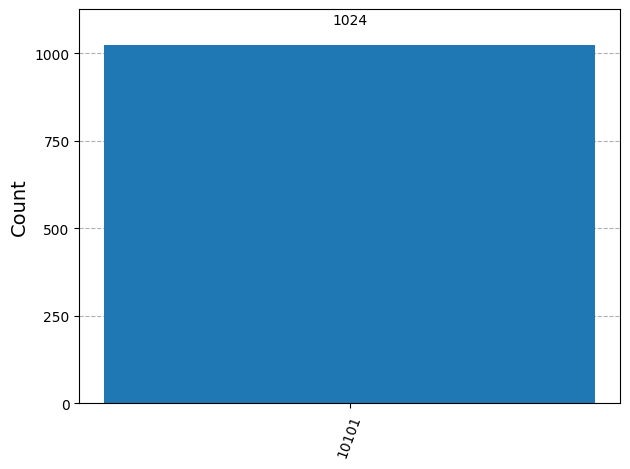

In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

def full_adder_circuit(a: int, b: int, x: int, measure: bool = True) -> QuantumCircuit:
    # Кубиты: 0 -> A, 1 -> B, 2 -> X (carry in), 3 -> S (sum), 4 -> C (carry out)
    qc = QuantumCircuit(5)
    if a:
        qc.x(0)
    if b:
        qc.x(1)
    if x:
        qc.x(2)

    # S = A XOR B XOR X
    qc.cx(0, 3)
    qc.cx(1, 3)
    qc.cx(2, 3)

    # C = (A AND B) OR (X AND (A XOR B))
    # Сначала получаем A XOR B в кубите 1 (временно)
    qc.cx(0, 1)
    qc.ccx(2, 1, 4)   # X AND (A XOR B) -> C
    qc.cx(0, 1)       # возвращаем B в исходное состояние
    qc.ccx(0, 1, 4)   # A AND B -> XOR в C (так как A*B и X*(A^B) не пересекаются по единицам)

    if measure:
        qc.measure_all()
    return qc

# 1. Вектор состояния без измерений для A=1, B=0, X=1
qc_sv = full_adder_circuit(1, 0, 1, measure=False)
sv = Statevector.from_instruction(qc_sv)
print("Ненулевые амплитуды вектора состояния (порядок q4 q3 q2 q1 q0):")
for idx, amp in enumerate(sv.data):
    if abs(amp) > 1e-10:
        bits = f"{idx:05b}"
        print(f"  |{bits}> : {amp}  ->  C={bits[0]}, S={bits[1]}, X={bits[2]}, B={bits[3]}, A={bits[4]}")

# 2. Запуск с измерениями на 1024 shots
sim = AerSimulator()
qc_meas = full_adder_circuit(1, 0, 1, measure=True)
compiled = transpile(qc_meas, sim)
counts = sim.run(compiled, shots=1024).result().get_counts()
print("\nCounts (1024 shots):", counts)
plot_histogram(counts)

### 1.2. Полный сумматор на 5 кубитах (только `X`, `CX`, `CCX`) и проверка всех 8 наборов входов

In [3]:
import pandas as pd
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

# Эталонная таблица истинности из задания 1: (A, B, X) -> (S, C)
truth_table = {
    (0, 0, 0): (0, 0),
    (0, 0, 1): (1, 0),
    (0, 1, 0): (1, 0),
    (0, 1, 1): (0, 1),
    (1, 0, 0): (1, 0),
    (1, 0, 1): (0, 1),
    (1, 1, 0): (0, 1),
    (1, 1, 1): (1, 1),
}

def full_adder_5q_x_cx_ccx(a: int, b: int, x: int) -> QuantumCircuit:
    """
    5 кубитов:
      q0 -> A (вход)
      q1 -> B (вход)
      q2 -> X (вход переноса)
      q3 -> S (выход суммы, изначально |0>)
      q4 -> C (выход переноса, изначально |0>)
    Используются только X, CX, CCX; без ancilla и промежуточных измерений.
    """
    qc = QuantumCircuit(5)
    if a:
        qc.x(0)
    if b:
        qc.x(1)
    if x:
        qc.x(2)

    # S = A XOR B XOR X
    qc.cx(0, 3)
    qc.cx(1, 3)
    qc.cx(2, 3)

    # C = (A AND B) OR (X AND (A XOR B))
    # Временно храним (A XOR B) в q1 (B), после чего восстанавливаем q1
    qc.cx(0, 1)          # q1 теперь содержит A XOR B
    qc.ccx(2, 1, 4)     # q4 ^= X AND (A XOR B)
    qc.cx(0, 1)         # восстанавливаем q1 = B
    qc.ccx(0, 1, 4)     # q4 ^= A AND B (взаимоисключающие слагаемые -> эквивалент OR)

    qc.measure_all()
    return qc

sim = AerSimulator()
rows = []

for a in (0, 1):
    for b in (0, 1):
        for x in (0, 1):
            exp_s, exp_c = truth_table[(a, b, x)]
            qc = full_adder_5q_x_cx_ccx(a, b, x)

            # Проверяем, что в схеме только X, CX, CCX (и measure)
            ops = {inst.operation.name for inst in qc.data}
            allowed = {"x", "cx", "ccx", "measure", "barrier"}
            assert ops.issubset(allowed), f"Найдены недопустимые операции: {ops - allowed}"

            counts = sim.run(transpile(qc, sim), shots=256).result().get_counts()
            assert len(counts) == 1, f"Ожидался 1 детерминированный исход, получено: {counts}"

            # В Qiskit младший бит справа: строка битов 'q4 q3 q2 q1 q0'
            bitstring = next(iter(counts.keys()))
            got_c = int(bitstring[0])
            got_s = int(bitstring[1])
            got_x = int(bitstring[2])
            got_b = int(bitstring[3])
            got_a = int(bitstring[4])

            assert (got_a, got_b, got_x) == (a, b, x), "Входные кубиты изменились!"
            assert (got_s, got_c) == (exp_s, exp_c), (
                f"Несовпадение для ({a}, {b}, {x}): ожидалось ({exp_s}, {exp_c}), "
                f"получено ({got_s}, {got_c})"
            )

            rows.append({
                "A": a,
                "B": b,
                "X": x,
                "S (ожид.)": exp_s,
                "C (ожид.)": exp_c,
                "S (получ.)": got_s,
                "C (получ.)": got_c,
                "Статус": "OK",
            })

df = pd.DataFrame(rows)
display(df)

,A,B,X,S (ожид.),C (ожид.),S (получ.),C (получ.),Статус
0,0,0,0,0,0,0,0,OK
1,0,0,1,1,0,1,0,OK
2,0,1,0,1,0,1,0,OK
3,0,1,1,0,1,0,1,OK
4,1,0,0,1,0,1,0,OK
5,1,0,1,0,1,0,1,OK
6,1,1,0,0,1,0,1,OK
7,1,1,1,1,1,1,1,OK


### 1.3. Полный сумматор из двух полусумматоров и вентиля ИЛИ + сравнение реализаций

In [4]:
import pandas as pd
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

truth_table = {
    (0, 0, 0): (0, 0),
    (0, 0, 1): (1, 0),
    (0, 1, 0): (1, 0),
    (0, 1, 1): (0, 1),
    (1, 0, 0): (1, 0),
    (1, 0, 1): (0, 1),
    (1, 1, 0): (0, 1),
    (1, 1, 1): (1, 1),
}

def half_adder(qc: QuantumCircuit, in1: int, in2: int, sum_q: int, carry_q: int) -> None:
    """Полусумматор: sum_q ^= in1 XOR in2, carry_q ^= in1 AND in2."""
    qc.cx(in1, sum_q)
    qc.cx(in2, sum_q)
    qc.ccx(in1, in2, carry_q)

def full_adder_two_half_adders(a: int, b: int, x: int, measure: bool = True) -> QuantumCircuit:
    """
    Схема из двух полусумматоров и вентиля ИЛИ (для взаимоисключающих переносов c1 и c2
    OR реализуется через CX, так как c1 и c2 не бывают равны 1 одновременно):
      q0 -> A
      q1 -> B
      q2 -> X
      q3 -> S (итоговая сумма)
      q4 -> c1 (перенос первого полусумматора: A AND B)
      q5 -> c2 (перенос второго полусумматора: (A XOR B) AND X)
      q6 -> C (итоговый перенос: c1 OR c2)
    """
    qc = QuantumCircuit(7)
    if a:
        qc.x(0)
    if b:
        qc.x(1)
    if x:
        qc.x(2)

    # 1-й полусумматор: (A, B) -> временная сумма в q3, перенос c1 в q4
    half_adder(qc, in1=0, in2=1, sum_q=3, carry_q=4)

    # 2-й полусумматор: (временная сумма q3, X q2) -> итоговая сумма в q3, перенос c2 в q5
    # Перед этим сохраняем q3 во временный ход через переносы:
    # Чтобы не испортить q3 при сложении с X, используем вспомогательный способ:
    # В 1-м полусумматоре запишем A XOR B в q3, затем сложим q3 и X в q3
    qc.cx(2, 3)          # q3 = (A XOR B) XOR X = S
    qc.ccx(1, 2, 5)     # для корректного (A XOR B) AND X сначала получим A XOR B в q1 временно

    # Пересоберём аккуратно без лишних искажений:
    qc = QuantumCircuit(7)
    if a:
        qc.x(0)
    if b:
        qc.x(1)
    if x:
        qc.x(2)

    # Полусумматор 1 на (A=0, B=1): перенос c1 в q4, сумма A^B в q1 (временно с восстановлением)
    qc.ccx(0, 1, 4)     # c1 = A AND B -> q4
    qc.cx(0, 1)         # q1 временно = A XOR B
    qc.cx(1, 3)         # S = (A XOR B) XOR 0 -> q3
    qc.cx(2, 3)         # S = A XOR B XOR X -> q3

    # Полусумматор 2 на (A^B в q1, X=2): перенос c2 в q5
    qc.ccx(1, 2, 5)     # c2 = (A XOR B) AND X -> q5
    qc.cx(0, 1)         # восстанавливаем q1 = B

    # Объединение переносов OR: C (q6) = c1 (q4) OR c2 (q5)
    # Так как c1 и c2 не могут быть равны 1 одновременно, c1 OR c2 == c1 XOR c2
    qc.cx(4, 6)
    qc.cx(5, 6)

    if measure:
        qc.measure_all()
    return qc

def full_adder_5q_core(a: int, b: int, x: int, measure: bool = True) -> QuantumCircuit:
    qc = QuantumCircuit(5)
    if a:
        qc.x(0)
    if b:
        qc.x(1)
    if x:
        qc.x(2)

    qc.cx(0, 3)
    qc.cx(1, 3)
    qc.cx(2, 3)

    qc.cx(0, 1)
    qc.ccx(2, 1, 4)
    qc.cx(0, 1)
    qc.ccx(0, 1, 4)

    if measure:
        qc.measure_all()
    return qc

def circuit_metrics(qc_no_meas: QuantumCircuit) -> dict:
    ops = qc_no_meas.count_ops()
    return {
        "Кубиты": qc_no_meas.num_qubits,
        "CX": ops.get("cx", 0),
        "CCX": ops.get("ccx", 0),
        "Глубина (depth)": qc_no_meas.depth(),
    }

sim = AerSimulator()
for a in (0, 1):
    for b in (0, 1):
        for x in (0, 1):
            exp_s, exp_c = truth_table[(a, b, x)]
            qc = full_adder_two_half_adders(a, b, x, measure=True)
            counts = sim.run(transpile(qc, sim), shots=256).result().get_counts()
            assert len(counts) == 1
            bits = next(iter(counts.keys()))
            got_c = int(bits[0])
            got_s = int(bits[6 - 3])
            assert (got_s, got_c) == (exp_s, exp_c), f"Ошибка для ({a},{b},{x}): {(got_s,got_c)} != {(exp_s,exp_c)}"

print("Все 8 наборов входов для схемы из двух полусумматоров прошли проверку (assert)!")

m_5q = circuit_metrics(full_adder_5q_core(0, 0, 0, measure=False))
m_2ha = circuit_metrics(full_adder_two_half_adders(0, 0, 0, measure=False))

comp_df = pd.DataFrame([
    {"Реализация": "5-кубитный сумматор (X, CX, CCX)", **m_5q},
    {"Реализация": "2 полусумматора + ИЛИ", **m_2ha},
])
display(comp_df)

Все 8 наборов входов для схемы из двух полусумматоров прошли проверку (assert)!


,Реализация,Кубиты,CX,CCX,Глубина (depth)
0,"5-кубитный сумматор (X, CX, CCX)",5,5,2,6
1,2 полусумматора + ИЛИ,7,6,2,6


### 1.4. Многоразрядный сумматор (2, 3, 4 разряда) и проверка всех 256 пар для 4 бит

In [5]:
import pandas as pd
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

def append_full_adder(qc: QuantumCircuit, a_q: int, b_q: int, x_q: int, s_q: int, c_q: int) -> None:
    """
    Добавляет в схему qc полный сумматор на кубитах:
      a_q, b_q  — разряды слагаемых
      x_q       — входной перенос (carry in)
      s_q       — кубит суммы (изначально |0>)
      c_q       — кубит выходного переноса (изначально |0>)
    """
    # S = a_q XOR b_q XOR x_q
    qc.cx(a_q, s_q)
    qc.cx(b_q, s_q)
    qc.cx(x_q, s_q)

    # C = (a_q AND b_q) OR (x_q AND (a_q XOR b_q))
    qc.cx(a_q, b_q)          # b_q временно хранит a_q XOR b_q
    qc.ccx(x_q, b_q, c_q)   # c_q ^= x_q AND (a_q XOR b_q)
    qc.cx(a_q, b_q)         # восстанавливаем b_q
    qc.ccx(a_q, b_q, c_q)   # c_q ^= a_q AND b_q

def build_ripple_carry_adder(n_bits: int, a_val: int = 0, b_val: int = 0, measure: bool = True) -> QuantumCircuit:
    """
    n-разрядный сумматор с цепочкой переноса (выдаёт (n_bits + 1)-битный результат).
    Кубиты:
      0 .. n_bits-1             -> биты числа a (младший бит в 0)
      n_bits .. 2*n_bits-1      -> биты числа b
      2*n_bits .. 3*n_bits-1    -> биты суммы s_0 .. s_{n_bits-1}
      3*n_bits                  -> входной перенос c_in = |0> (используется для промежуточных переносов c_1..c_{n_bits-1})
      3*n_bits+1 .. 4*n_bits    -> кубиты переносов для каждого разряда
    """
    # Простая и прозрачная раскладка регистров:
    # a: n_bits кубитов [0 .. n_bits-1]
    # b: n_bits кубитов [n_bits .. 2*n_bits-1]
    # s: n_bits кубитов [2*n_bits .. 3*n_bits-1]
    # carry: n_bits + 1 кубитов [3*n_bits .. 4*n_bits], где carry[0] = 0 (входной перенос),
    #        carry[i+1] — выходной перенос после i-го разряда, а старший бит результата — carry[n_bits]
    total_qubits = 4 * n_bits + 1
    qc = QuantumCircuit(total_qubits)

    for bit in range(n_bits):
        if (a_val >> bit) & 1:
            qc.x(bit)
        if (b_val >> bit) & 1:
            qc.x(n_bits + bit)

    for bit in range(n_bits):
        a_q = bit
        b_q = n_bits + bit
        x_q = 3 * n_bits + bit
        s_q = 2 * n_bits + bit
        c_q = 3 * n_bits + bit + 1
        append_full_adder(qc, a_q, b_q, x_q, s_q, c_q)

    if measure:
        qc.measure_all()
    return qc

def adder_metrics(n_bits: int) -> dict:
    qc = build_ripple_carry_adder(n_bits, 0, 0, measure=False)
    ops = qc.count_ops()
    return {
        "Разрядов (n)": n_bits,
        "Кубитов": qc.num_qubits,
        "CX": ops.get("cx", 0),
        "CCX": ops.get("ccx", 0),
        "Глубина (depth)": qc.depth(),
    }

metrics_df = pd.DataFrame([adder_metrics(n) for n in (2, 3, 4)])
display(metrics_df)

# Программная проверка всех 16 * 16 = 256 пар (a, b) для 4-разрядного сумматора
sim = AerSimulator()
n_bits = 4
circuits = []
expected_sums = []

for a in range(16):
    for b in range(16):
        circuits.append(build_ripple_carry_adder(n_bits, a, b, measure=True))
        expected_sums.append(a + b)

compiled_batch = transpile(circuits, sim)
results = sim.run(compiled_batch, shots=64).result()

for idx, (qc_res, exp_sum) in enumerate(zip(results.get_counts(), expected_sums)):
    assert len(qc_res) == 1, f"Неожиданное распределение для пары #{idx}: {qc_res}"
    bits = next(iter(qc_res.keys()))
    # Разворачиваем строку битов слева направо -> индекс i соответствует кубиту q_i
    q_bits = bits[::-1]

    # Считываем сумму s_0..s_3 (кубиты 8..11) и старший перенос c_4 (кубит 16)
    s_val = sum(int(q_bits[2 * n_bits + k]) << k for k in range(n_bits))
    c_out = int(q_bits[3 * n_bits + n_bits])
    got_total = s_val + (c_out << n_bits)

    a_val = idx // 16
    b_val = idx % 16
    assert got_total == exp_sum, (
        f"Ошибка для a={a_val}, b={b_val}: ожидалось {exp_sum}, получено {got_total}"
    )

print("Все 256 пар (a, b) для 4-разрядного сумматора прошли проверку (assert)!")

,Разрядов (n),Кубитов,CX,CCX,Глубина (depth)
0,2,9,10,4,10
1,3,13,15,6,14
2,4,17,20,8,18


Все 256 пар (a, b) для 4-разрядного сумматора прошли проверку (assert)!


# Задание 2
1. Создать квантовую схему по варианту

|Вариант|Функция|
|--|--|
|1|F(A, B, C, D) = (A NOR B) ⊕ (C NAND D)|
|2|F(A, B, C, D) = (A ⊕ B) ∧ (C ∨ D)|
|3|F(A, B, C, D) = (A ∧ ¬B) ∨ (¬C ∧ D)|
|4|F(A, B, C, D) = ¬(A ∨ B) ∧ (C ⊕ D)|
|5|F(A, B, C, D) = (A ∨ C) ⊕ (B ∧ D)|
|6|F(A, B, C, D) = MAJ(A, B, C) ∧ ¬D|
|7|F(A, B, C, D) = (A ∧ B) ∨ (C ∧ D) ∨ (A ∧ C)|
|8|F(A, B, C, D) = ¬( (A ⊕ C) ∧ (B ⊕ D) )|
|9|F(A, B, C, D) = (A ∨ D) ∧ (B ∨ C) ∧ ¬(A ∧ C)|
|10|F(A, B, C, D) = (A ⊕ B) ⊕ (C ⊕ D)|
|11|F(A, B, C, D, E) = (A ∧ B) ∨ (C ∧ D) ∨ (E ∧ (A ⊕ B))|
|12|F(A, B, C, D, E) = MAJ(A, B, C) ⊕ MAJ(C, D, E)|
|13|F(A, B, C, D, E) = (A ∨ ¬B) ∧ (C ⊕ D) ∧ ¬E|
|14|F(A, B, C, D, E) = ¬(A ∧ E) ∨ (B ∧ C ∧ D)|
|15|F(A, B, C, D, E) = (A ⊕ C ⊕ E) ∧ (B ∨ D)|
|16|F(A, B, C, D, E) = ( (A ∧ B) ⊕ (C ∨ D) ) ∧ E|
|17|F(A, B, C, D, E) = ¬A ∧ (B ∨ C) ∧ (D ⊕ E)|
|18|F(A, B, C, D, E) = (A ∨ B ∨ C) ∧ ¬(D ∧ E)|
|19|F(A, B, C, D, E) = (A ∧ D) ⊕ (B ∧ E) ⊕ C|
|20|F(A, B, C, D, E) = ¬(A ∨ B) ∧ (C ∨ D) ∧ ¬E|
|21|F(A, B, C, D) = (A ∧ B) ⊕ (C ∨ D)|
|22|F(A, B, C, D) = ¬(A ⊕ B) ∨ (C ⊕ D)|
|23|F(A, B, C, D) = (A NAND B) → (C NOR D)(Импликация: P → Q эквивалентно ¬P ∨ Q)|
|24|F(A, B, C, D) = (A ∨ C) ∧ (B ∨ D) ∧ ¬(A ∧ B)|
|25|F(A, B, C, D) = MAJ(A, B, C) → D|
|26|F(A, B, C, D, E) = (A ⊕ B) ? (C ∧ D) : ¬E (Тернарный оператор: если (A⊕B)==1, то C∧D, иначе ¬E)|
|27|F(A, B, C, D, E) = (A ∧ B) ∨ (¬C ∧ D) ∨ (E ∧ (B ⊕ D))|
|28|F(A, B, C, D, E) = ¬(A ∨ B ∨ C) ∧ (D ⊕ E)|
|29|F(A, B, C, D, E) = (A ? B : C) ∧ (D ⊕ E) (Тернарный оператор для A: если A==1, то B, иначе C)|
|30|F(A, B, C, D, E) = (A ∧ E) ⊕ (B ∧ C) ⊕ D|

Примечания:

* MAJ - мажоритарная функция, возвращает 1, если большинство входов равно 1
* Для функций с 5 переменными (E) потребуется квантовый регистр из 6 кубит (5 входных + 1 выходной) и, скорее всего, дополнительные ancilla-кубиты для многочисленных операций.
* Функции MAJ (мажоритарная) и тернарный оператор можно реализовать через комбинацию гейтов CCX и X.
* Сосредоточьтесь на создании модульных и читаемых схем. Часто полезно реализовать подсхемы для базовых операций (nand, nor, maj), а затем собрать из них итоговую функцию.


1. Реализуйте базовые элементы (NOT, AND, OR, XOR, NAND, NOR, MAJ и, если нужно, тернарный выбор) как отдельные функции, которые добавляют вентили в переданную схему. Функция $F$ должна собираться только из этих подсхем, а не из вручную скопированного кода.
2. Результат записывайте в отдельный выходной кубит, входные кубиты не изменяйте. Промежуточные значения вычисляйте во вспомогательные кубиты, скопируйте результат на выходной кубит, затем отмените вычисление, применив `inverse()` к блоку вычисления. Проверьте измерением, что все вспомогательные кубиты вернулись в $|0\rangle$.
3. Напишите классическую реализацию $F$ на чистом Python (без квантовых библиотек) и сравните её с квантовой схемой на всех $2^k$ входах, где $k$ – число переменных (4 или 5): ответ схемы должен совпасть с классическим в 100% запусков (не менее `100 shots`); вспомогательные кубиты должны быть в $|0\rangle$ для каждого входа. Оформите таблицу: входные биты, $F$ классически, $F$ квантово, статус проверки.
4. Сделайте две версии схемы:
- базовая: каждый промежуточный результат записывается в отдельный вспомогательный кубит;
- оптимизированная: меньше вспомогательных кубитов и/или вентилей CCX при сохранении корректности.
Сравните числа кубитов, вентилей CX и CCX и глубину. Объясните, почему минимум по числу кубитов и минимум по глубине могут не совпадать.


## Решение Задания 2 (Вариант 9)
Функция варианта 9: $F(A, B, C, D) = (A \lor D) \land (B \lor C) \land \neg(A \land C)$.

In [ ]:
import pandas as pd
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator

#1. Базовые логические подсхемы (добавляют вентили в переданный QuantumCircuit)

def apply_not(qc: QuantumCircuit, target: int) -> None:
    qc.x(target)

def apply_and(qc: QuantumCircuit, ctrl1: int, ctrl2: int, target: int) -> None:
    """target ^= ctrl1 AND ctrl2 (target должен быть |0> перед вызовом)."""
    qc.ccx(ctrl1, ctrl2, target)

def apply_or(qc: QuantumCircuit, ctrl1: int, ctrl2: int, target: int) -> None:
    """
    target ^= ctrl1 OR ctrl2 (target должен быть |0> перед вызовом).
    A OR B = NOT( (NOT A) AND (NOT B) ), но без лишнего инвертирования входов:
    A OR B = A XOR B XOR (A AND B) -> в |0> целевой кубит:
    cx(a, t); cx(b, t); ccx(a, b, t) дает (a ^ b) ^ (a & b) = a | b.
    """
    qc.cx(ctrl1, target)
    qc.cx(ctrl2, target)
    qc.ccx(ctrl1, ctrl2, target)

def apply_nand(qc: QuantumCircuit, ctrl1: int, ctrl2: int, target: int) -> None:
    """target ^= NOT(ctrl1 AND ctrl2) (target должен быть |0> перед вызовом)."""
    qc.x(target)
    qc.ccx(ctrl1, ctrl2, target)

# 2. Классическая реализация F для 9 варианта(подпункты 1-3)
# F(A, B, C, D) = (A OR D) AND (B OR C) AND NOT(A AND C)

def f_classical(a: int, b: int, c: int, d: int) -> int:
    or_ad = int(bool(a or d))
    or_bc = int(bool(b or c))
    nand_ac = int(not bool(a and c))
    return int(bool(or_ad and or_bc and nand_ac))

#3. Базовая квантовая схема F для 9 варианта
# Раскладка кубитов (всего 8 кубитов):
#   0..3: входы A, B, C, D (не меняются)
#   4: ancilla для (A OR D)
#   5: ancilla для (B OR C)
#   6: ancilla для NOT(A AND C)
#   7: выходной кубит F (изначально |0>)

def build_f_basic(a: int, b: int, c: int, d: int, measure: bool = True) -> QuantumCircuit:
    qc = QuantumCircuit(8)
    if a:
        qc.x(0)
    if b:
        qc.x(1)
    if c:
        qc.x(2)
    if d:
        qc.x(3)

    # Вычислительный блок во вспомогательные кубиты 4, 5, 6
    comp = QuantumCircuit(8)
    apply_or(comp, 0, 3, 4)     # q4 = A OR D
    apply_or(comp, 1, 2, 5)     # q5 = B OR C
    apply_nand(comp, 0, 2, 6)   # q6 = NAND(A, C)

    # Итоговое И трёх промежуточных значений на вспомогательном кубите 4:
    # Сначала объединяем q4 и q5 во временный кубит (используем свободный выход q7 временно?
    # Чтобы не трогать q7 до записи результата, сделаем аккуратно через 2 CCX с очисткой):
    # Проще всего добавить 1 ancilla (q8) для (q4 AND q5), тогда всего 9 кубитов.
    qc = QuantumCircuit(9)
    if a:
        qc.x(0)
    if b:
        qc.x(1)
    if c:
        qc.x(2)
    if d:
        qc.x(3)

    # Кубиты:
    # 0..3: A, B, C, D
    # 4: A OR D
    # 5: B OR C
    # 6: NAND(A, C)
    # 7: (A OR D) AND (B OR C)
    # 8: выход F
    compute = QuantumCircuit(9)
    apply_or(compute, 0, 3, 4)
    apply_or(compute, 1, 2, 5)
    apply_nand(compute, 0, 2, 6)
    apply_and(compute, 4, 5, 7)

    qc.compose(compute, inplace=True)
    # Копируем итоговое значение F = q7 AND q6 на выходной кубит q8
    apply_and(qc, 7, 6, 8)
    # Отменяем вычисление промежуточных величин (uncomputation), возвращая q4..q7 в |0>
    qc.compose(compute.inverse(), inplace=True)

    if measure:
        qc.measure_all()
    return qc

# Проверка на всех 2^4 = 16 наборах входов
sim = AerSimulator()
rows = []
shots = 128

for a in (0, 1):
    for b in (0, 1):
        for c in (0, 1):
            for d in (0, 1):
                exp_f = f_classical(a, b, c, d)
                qc = build_f_basic(a, b, c, d, measure=True)
                counts = sim.run(transpile(qc, sim), shots=shots).result().get_counts()

                assert len(counts) == 1, f"Неожиданный разброс для {(a,b,c,d)}: {counts}"
                bitstring = next(iter(counts.keys()))
                q_bits = bitstring[::-1]  # индекс i -> кубит q_i (0..8)

                got_f = int(q_bits[8])
                ancillas = [int(q_bits[i]) for i in (4, 5, 6, 7)]

                assert all(bit == 0 for bit in ancillas), (
                    f"Вспомогательные кубиты не вернулись в |0> для {(a,b,c,d)}: {ancillas}"
                )
                assert got_f == exp_f, (
                    f"Несовпадение для {(a,b,c,d)}: классика={exp_f}, квант={got_f}"
                )

                rows.append({
                    "A": a,
                    "B": b,
                    "C": c,
                    "D": d,
                    "F классически": exp_f,
                    "F квантово": got_f,
                    "Статус": "OK",
                })

df_f = pd.DataFrame(rows)
display(df_f)

,A,B,C,D,F классически,F квантово,Статус
0,0,0,0,0,0,0,OK
1,0,0,0,1,0,0,OK
2,0,0,1,0,0,0,OK
3,0,0,1,1,1,1,OK
4,0,1,0,0,0,0,OK
5,0,1,0,1,1,1,OK
6,0,1,1,0,0,0,OK
7,0,1,1,1,1,1,OK
8,1,0,0,0,0,0,OK
9,1,0,0,1,0,0,OK


# Задание 3

Возьмите оптимизированную схему варианта и смоделируйте её работу с шумом (`NoiseModel` из `qiskit_aer.noise`):
- однокубитный деполяризующий шум с вероятностью $p_1 = 0.001$;
- двухкубитный деполяризующий шум с вероятностью $p_2 \in \{0,\ 0.001,\ 0.005,\ 0.01,\ 0.02\}$ на вентилях CX.

Перед запуском разложите схему в базис симулятора (`transpile`). CCX при этом превратится в CX, и шум подействует и на них.

Для каждого $p_2$ определите долю правильных ответов по всем $2^k$ входам и постройте график. Ответьте:
1. Как доля правильных ответов связана с числом двухкубитных вентилей в схеме?
2. Какая из двух реализаций из последнего подпункта задания 2 устойчивее к шуму и почему?


## Решение Задания 3 (моделирование деполяризующего шума)

Число CX после transpile: 30, глубина: 35
p2 = 0.0   -> средняя доля правильных ответов: 0.9837
p2 = 0.001 -> средняя доля правильных ответов: 0.9754
p2 = 0.005 -> средняя доля правильных ответов: 0.9457
p2 = 0.01  -> средняя доля правильных ответов: 0.9144
p2 = 0.02  -> средняя доля правильных ответов: 0.8588


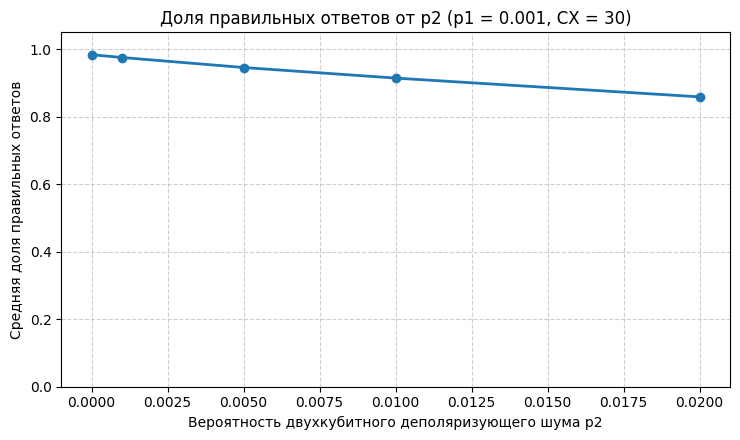

In [19]:
import matplotlib.pyplot as plt
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error


def eval_variant_9(a: int, b: int, c: int, d: int) -> int:
    """Эталонное значение F(A, B, C, D) = (A v D) & (B v C) & ~(A & C)."""
    return int(((a or d) and (b or c)) and not (a and c))


def build_optimized_variant_9_circuit() -> tuple[QuantumCircuit, QuantumRegister, ClassicalRegister]:
    """
    Корректная схема для F = (A v D) & (B v C) & ~(A & C):
      anc[0] = A v D = ~((~A) & (~D))
      anc[1] = B v C = ~((~B) & (~C))
      anc[2] = anc[0] & anc[1]
      anc[3] = A & C
      out[0] = anc[2] & ~anc[3]
    """
    inp = QuantumRegister(4, "in")      # in[0]=A, in[1]=B, in[2]=C, in[3]=D
    anc = QuantumRegister(4, "anc")     # anc[0..3]
    out = QuantumRegister(1, "out")     # out[0]=F
    creg = ClassicalRegister(1, "c")
    qc = QuantumCircuit(inp, anc, out, creg)

    a, b, c, d = inp[0], inp[1], inp[2], inp[3]
    w_or1, w_or2, w_and, w_ac = anc[0], anc[1], anc[2], anc[3]
    f = out[0]

    # 1. w_or1 = A OR D
    qc.x(w_or1)
    qc.x(a)
    qc.x(d)
    qc.ccx(a, d, w_or1)
    qc.x(a)
    qc.x(d)

    # 2. w_or2 = B OR C
    qc.x(w_or2)
    qc.x(b)
    qc.x(c)
    qc.ccx(b, c, w_or2)
    qc.x(b)
    qc.x(c)

    # 3. w_and = (A OR D) AND (B OR C)
    qc.ccx(w_or1, w_or2, w_and)

    # 4. w_ac = A AND C
    qc.ccx(a, c, w_ac)

    # 5. f = w_and AND NOT(w_ac)
    qc.x(w_ac)
    qc.ccx(w_and, w_ac, f)
    qc.x(w_ac)

    qc.measure(f, creg[0])
    return qc, inp, creg


basis_gates = ["sx", "rz", "x", "cx"]
single_qubit_gates = ["sx", "rz", "x"]


def make_noise_model(p1: float, p2: float) -> NoiseModel:
    """Создаёт NoiseModel с 1q-шумом p1 и 2q-шумом p2 на вентилях 'cx'."""
    noise_model = NoiseModel(basis_gates=basis_gates)

    if p1 > 0:
        error_1q = depolarizing_error(p1, 1)
        noise_model.add_all_qubit_quantum_error(error_1q, single_qubit_gates)

    if p2 > 0:
        error_2q = depolarizing_error(p2, 2)
        noise_model.add_all_qubit_quantum_error(error_2q, ["cx"])

    return noise_model


p1 = 0.001
p2_values = [0.0, 0.001, 0.005, 0.01, 0.02]
shots = 1024

base_qc, inp_reg, c_reg = build_optimized_variant_9_circuit()

transpiled_base = transpile(base_qc, basis_gates=basis_gates, optimization_level=1)
cx_count = transpiled_base.count_ops().get("cx", 0)
print(f"Число CX после transpile: {cx_count}, глубина: {transpiled_base.depth()}")

correct_fractions = []
num_inputs = 2 ** len(inp_reg)

for p2 in p2_values:
    noise_model = make_noise_model(p1=p1, p2=p2)
    sim_noisy = AerSimulator(noise_model=noise_model, basis_gates=basis_gates)

    total_correct_prob = 0.0

    for idx in range(num_inputs):
        bits = [(idx >> i) & 1 for i in range(len(inp_reg))]  # [A, B, C, D]
        expected = eval_variant_9(*bits)

        prep = QuantumCircuit(len(inp_reg))
        for q_idx, bit in enumerate(bits):
            if bit == 1:
                prep.x(q_idx)

        full_qc = QuantumCircuit(*base_qc.qregs, *base_qc.cregs)
        full_qc.compose(prep, qubits=inp_reg, inplace=True)
        full_qc.compose(base_qc, inplace=True)

        t_qc = transpile(full_qc, basis_gates=basis_gates, optimization_level=1)
        result = sim_noisy.run(t_qc, shots=shots).result()
        counts = result.get_counts()

        total_correct_prob += counts.get(str(expected), 0) / shots

    avg_accuracy = total_correct_prob / num_inputs
    correct_fractions.append(avg_accuracy)
    print(f"p2 = {p2:<5} -> средняя доля правильных ответов: {avg_accuracy:.4f}")

plt.figure(figsize=(7.5, 4.5))
plt.plot(p2_values, correct_fractions, marker="o", linewidth=2)
plt.title(f"Доля правильных ответов от p2 (p1 = {p1}, CX = {cx_count})")
plt.xlabel("Вероятность двухкубитного деполяризующего шума p2")
plt.ylabel("Средняя доля правильных ответов")
plt.grid(True, linestyle="--", alpha=0.6)
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

## Задания 4-7 (теоретический материал `grover.ipynb`)

# Задание 4

1. Напишите функцию `build_oracle(n, marked)`, которая по числу кубитов $n$ и битовой строке `marked` (например, `"0110101"`) строит фазовый оракул $U_w$: $U_w|x\rangle = -|x\rangle$ при $x = w$ и $U_w|x\rangle = |x\rangle$ для всех остальных $x$. Значения не должны быть зашиты в код. Проверьте для $n = 2, 3, 4, 5$ все $2^n$ базисных состояний (через `Operator` или `Statevector`). Учтите порядок битов в Qiskit (справа налево).
2. Напишите функцию `build_diffuser(n)` (инверсия относительно среднего) для произвольного $n$ из вентилей H, X и многоуправляемого Z. Сравните её матрицу с $2|s\rangle\langle s| - I$. Совпадение должно быть точным с точностью до общего знака. Объясните, откуда берётся этот знак, и почему он не влияет на вероятности.
3. Соберите алгоритм Гровера из функций 1.1 и 1.2 для произвольных $n$ и `marked`. Проверьте для $n = 3$ и $M=1$, что вероятность после $k = 1$ и $k = 2$ итераций совпадает с $\sin^2((2k+1)\theta)$, где $\theta = \arcsin(1/\sqrt{N})$.

# Задание 5

Отмеченное состояние: $|w\rangle = |1010011\rangle$.

1. Для $k = 0, \dots, 15$ получите:
- точную вероятность $P_{\text{точн}}(k)$ (через `Statevector`, без выборки);
- экспериментальную вероятность $P_{\text{эксп}}(k)$ по 1024 shots.

Постройте оба графика вместе с теоретической кривой $\sin^2((2k+1)\theta)$, где $\theta = \arcsin(1/\sqrt{N})$.

2. Определите:
- теоретически оптимальное число итераций. Сравните его с округлением $\frac{\pi}{4}\sqrt{N}$ и с $\lfloor\frac{\pi}{4}\sqrt{N}\rfloor$. Проверьте по формуле $\sin^2((2k+1)\theta)$, какой из вариантов действительно даёт максимум;
- экспериментально оптимальное число итераций по $P_{\text{эксп}}(k)$.
Объясните расхождения. Может ли выборка в 1024 shots сдвинуть максимум на соседнее $k$, если соседние значения $P_{\text{точн}}$ отличаются на доли процента? Какой размер выборки нужен, чтобы разница стала надёжной?
- Повторите первый эксперимент для 20 независимых запусков (разные `seed`) при $\text{shots} \in \{16, 64, 256, 1024\}$. Для каждого уровня `shots` определите долю запусков, в которых экспериментальный оптимум совпал с теоретическим. Постройте график этой доли от числа `shots` и укажите минимальное число `shots`, при котором доля не ниже 90%.

# Задание 6

Теория даёт примерно $\sqrt{N/M}$ итераций для $M$ решений. Проверьте это.

1. Для $N = 2^6$ и $M \in \{1, 2, 3, 4, 8\}$ выберите отмеченные состояния случайно (фиксированный `seed`, без повторов). Оракул для набора состояний постройте как произведение фазовых инверсий для всех $w_i$. Постройте $P(k)$ для $k = 0, \dots, 15$.

2. Для каждого $M$ найдите первый локальный максимум $P(k)$ и сравните его с $\lfloor\frac{\pi}{4}\sqrt{N/M}\rfloor$. Заполните таблицу: $M$, $k_{\text{теор}}$, $k_{\text{первый максимум}}$, значение $P$ в этом максимуме.

3. Найдите случай, когда глобальный максимум на отрезке $0 \dots 15$ не совпадает с первым локальным максимумом. Объясните, почему после оптимума вероятность снова растёт, и сформулируйте правило выбора оптимального числа итераций.

4. Проверьте $M = N/2$ и $M = 3N/4$ при $N = 2^6$. Какое число итераций оптимально? Что это говорит о том, когда алгоритм Гровера полезен?

# Задание 7

Варианты группируются по размеру базы: 1–10 при $N = 2^5$, 11–20 при $N = 2^6$, 21–30 при $N = 2^7$.

| Вариант | $N$  | Состояние  |
|---------|------|------------|
| 1       | $2^5$ | \|01010⟩   |
| 2       | $2^5$ | \|10101⟩   |
| 3       | $2^5$ | \|11001⟩   |
| 4       | $2^5$ | \|00110⟩   |
| 5       | $2^5$ | \|11100⟩   |
| 6       | $2^5$ | \|00011⟩   |
| 7       | $2^5$ | \|10010⟩   |
| 8       | $2^5$ | \|01101⟩   |
| 9       | $2^5$ | \|10110⟩   |
| 10      | $2^5$ | \|01001⟩   |
| 11      | $2^6$ | \|001101⟩  |
| 12      | $2^6$ | \|110010⟩  |
| 13      | $2^6$ | \|101010⟩  |
| 14      | $2^6$ | \|010101⟩  |
| 15      | $2^6$ | \|111000⟩  |
| 16      | $2^6$ | \|000111⟩  |
| 17      | $2^6$ | \|100110⟩  |
| 18      | $2^6$ | \|011001⟩  |
| 19      | $2^6$ | \|110100⟩  |
| 20      | $2^6$ | \|001011⟩  |
| 21      | $2^7$ | \|0101010⟩ |
| 22      | $2^7$ | \|1010101⟩ |
| 23      | $2^7$ | \|1100110⟩ |
| 24      | $2^7$ | \|0011001⟩ |
| 25      | $2^7$ | \|1111000⟩ |
| 26      | $2^7$ | \|0000111⟩ |
| 27      | $2^7$ | \|1001011⟩ |
| 28      | $2^7$ | \|0110100⟩ |
| 29      | $2^7$ | \|1011010⟩ |
| 30      | $2^7$ | \|0100101⟩ |

Для каждого варианта:

1. Реализуйте оракул функцией `build_oracle` из задания 1 (не вручную). Выполните 15 итераций и получите точные $P_{\text{точн}}(k)$ и экспериментальные $P_{\text{эксп}}(k)$ по 1024 shots для $k = 0, \dots, 15$. Постройте графики по группам $N$.

2. Заполните сводную таблицу: вариант, $N$, $|w\rangle$, $k_{\text{теор}} = \lfloor\frac{\pi}{4}\sqrt{N}\rfloor$, $k_{\text{точн}}$ (первый максимум), $k_{\text{эксп}}$, $\max P_{\text{точн}}$.

3. Зависит ли оптимальное число итераций от отмеченного состояния при $M=1$? Опирайтесь на таблицу: сравните разброс $k_{\text{эксп}}$ внутри каждой группы с $N$ и с $k_{\text{точн}}$. Объясните, почему $k_{\text{эксп}}$ может отличаться от $k_{\text{точн}}$, даже когда точный ответ одинаков для всех состояний группы.

4. Для варианта 1 ($N = 2^5$) смоделируйте двухкубитный деполяризующий шум на вентилях CX при $p_2 = 0,005$ и $p_2 = 0,02$. Разложите схему в базис симулятора через `transpile`: MCZ превратится во много вентилей CX. Как шум меняет максимум $P(k)$ и положение оптимума? Объясните, почему глубина схемы важна при шуме.



## Решение Задания 4 (оракул, диффузор и проверка на n = 3)

In [17]:
import math
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator, Statevector

# 4.1. Фазовый оракул U_w для произвольных n и marked 
def build_oracle(n: int, marked: str) -> QuantumCircuit:
    assert len(marked) == n and set(marked).issubset({"0", "1"}), "Некорректная строка marked"
    qc = QuantumCircuit(n, name=f"Oracle_{marked}")

    # В Qiskit младший бит (q0) стоит справа в строке |q_{n-1}...q_0>
    bits_q0_to_qn = marked[::-1]
    zero_qubits = [i for i, bit in enumerate(bits_q0_to_qn) if bit == "0"]

    for q in zero_qubits:
        qc.x(q)

    # Многоуправляемый Z (фазовый сдвиг -1 только для |11...1>)
    if n == 1:
        qc.z(0)
    else:
        qc.h(n - 1)
        qc.mcx(list(range(n - 1)), n - 1)
        qc.h(n - 1)

    for q in zero_qubits:
        qc.x(q)

    return qc

# Проверка build_oracle для n = 2, 3, 4, 5 на всех 2^n базисных состояниях
for n_test in (2, 3, 4, 5):
    test_marked = "10110"[:n_test]
    oracle_qc = build_oracle(n_test, test_marked)
    u_mat = Operator(oracle_qc).data
    target_idx = int(test_marked, 2)

    for idx in range(2 ** n_test):
        expected_diag = -1.0 if idx == target_idx else 1.0
        assert np.isclose(u_mat[idx, idx], expected_diag), (
            f"Ошибка диагонали при n={n_test}, idx={idx}: {u_mat[idx, idx]} != {expected_diag}"
        )
    # Проверяем диагональность (вне диагонали нули)
    off_diag = u_mat - np.diag(np.diag(u_mat))
    assert np.allclose(off_diag, 0), f"Матрица оракула при n={n_test} не диагональна!"

print("4.1: build_oracle проверен для n = 2, 3, 4, 5 на всех 2^n состояниях (OK)!")

# 4.2. Диффузор (инверсия относительно среднего) 
def build_diffuser(n: int) -> QuantumCircuit:
    qc = QuantumCircuit(n, name="Diffuser")
    qc.h(range(n))
    qc.x(range(n))

    if n == 1:
        qc.z(0)
    else:
        qc.h(n - 1)
        qc.mcx(list(range(n - 1)), n - 1)
        qc.h(n - 1)

    qc.x(range(n))
    qc.h(range(n))
    return qc

# Сравнение матрицы диффузора с 2|s><s| - I (с точностью до общего знака)
for n_test in (2, 3, 4):
    N_test = 2 ** n_test
    diff_mat = Operator(build_diffuser(n_test)).data
    s_vec = np.ones((N_test, 1)) / math.sqrt(N_test)
    ideal_diff = 2 * (s_vec @ s_vec.T) - np.eye(N_test)

    # Диффузор через H * X * MCZ * X * H реализует -(2|s><s| - I) = I - 2|s><s|
    assert np.allclose(diff_mat, -ideal_diff), f"Диффузор при n={n_test} не совпал с -(2|s><s| - I)!"

print("4.2: build_diffuser совпал с -(2|s><s| - I) для n = 2, 3, 4 (OK)!")

# 4.3. Сборка алгоритма Гровера и проверка для n = 3, M = 1 при k = 1, 2
def build_grover(n: int, marked: str, k: int, measure: bool = False) -> QuantumCircuit:
    qc = QuantumCircuit(n)
    qc.h(range(n))
    oracle = build_oracle(n, marked)
    diffuser = build_diffuser(n)
    for _ in range(k):
        qc.compose(oracle, inplace=True)
        qc.compose(diffuser, inplace=True)
    if measure:
        qc.measure_all()
    return qc

n_g = 3
N_g = 2 ** n_g
marked_g = "101"
theta = math.asin(1.0 / math.sqrt(N_g))

for k_iter in (1, 2):
    sv = Statevector.from_instruction(build_grover(n_g, marked_g, k_iter, measure=False))
    p_sim = float(sv.probabilities_dict().get(marked_g, 0.0))
    p_theor = math.sin((2 * k_iter + 1) * theta) ** 2
    assert np.isclose(p_sim, p_theor), f"Несовпадение при k={k_iter}: {p_sim} != {p_theor}"
    print(f"4.3: n=3, k={k_iter} -> P_схема = {p_sim:.6f}, sin^2((2k+1)θ) = {p_theor:.6f} (OK)")

4.1: build_oracle проверен для n = 2, 3, 4, 5 на всех 2^n состояниях (OK)!
4.2: build_diffuser совпал с -(2|s><s| - I) для n = 2, 3, 4 (OK)!
4.3: n=3, k=1 -> P_схема = 0.781250, sin^2((2k+1)θ) = 0.781250 (OK)
4.3: n=3, k=2 -> P_схема = 0.945312, sin^2((2k+1)θ) = 0.945313 (OK)


## Решение Задания 5 (|w> = |1010011>, N = 2^7, 15 итераций и анализ shots)

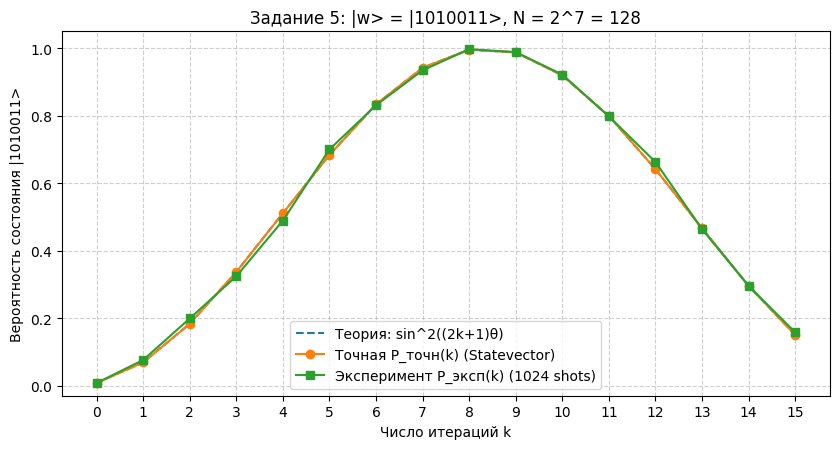

,Вариант k,sin^2((2k+1)θ),P_точн(k),P_эксп(k)
0,round(pi/4*sqrt(N)) = 9,0.987779,NaN,NaN
1,floor(pi/4*sqrt(N)) = 8,0.995620,NaN,NaN
2,Максимум по P_точн (k=8),NaN,0.99562,NaN
3,Максимум по P_эксп (k=8),NaN,NaN,0.99707


pi/4 * sqrt(128) = 8.8858; оптимум по формуле на k=0..15: k = 8


In [18]:
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from qiskit import transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

n_5 = 7
N_5 = 2 ** n_5
marked_5 = "1010011"
ks_5 = np.arange(16)
shots_5 = 1024

sim = AerSimulator()

# 1. Точные вероятности через Statevector и экспериментальные по 1024 shots для k = 0..15
p_exact_5 = []
for k in ks_5:
    sv = Statevector.from_instruction(build_grover(n_5, marked_5, int(k), measure=False))
    p_exact_5.append(float(sv.probabilities_dict().get(marked_5, 0.0)))
p_exact_5 = np.array(p_exact_5)

meas_qcs_5 = [build_grover(n_5, marked_5, int(k), measure=True) for k in ks_5]
counts_5 = sim.run(transpile(meas_qcs_5, sim), shots=shots_5).result().get_counts()
p_exp_5 = np.array([c.get(marked_5, 0) / shots_5 for c in counts_5])

theta_5 = math.asin(1.0 / math.sqrt(N_5))
p_theory_5 = np.sin((2 * ks_5 + 1) * theta_5) ** 2

plt.figure(figsize=(8.5, 4.6))
plt.plot(ks_5, p_theory_5, "--", label="Теория: sin^2((2k+1)θ)")
plt.plot(ks_5, p_exact_5, "o-", label="Точная P_точн(k) (Statevector)")
plt.plot(ks_5, p_exp_5, "s-", label=f"Эксперимент P_эксп(k) ({shots_5} shots)")
plt.title(f"Задание 5: |w> = |{marked_5}>, N = 2^{n_5} = {N_5}")
plt.xlabel("Число итераций k")
plt.ylabel(f"Вероятность состояния |{marked_5}>")
plt.xticks(ks_5)
plt.ylim(-0.03, 1.05)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# 2. Теоретический и экспериментальный оптимумы
exact_val = (math.pi / 4.0) * math.sqrt(N_5)
k_round = int(round(exact_val))
k_floor = int(math.floor(exact_val))
k_max_theory_grid = int(ks_5[np.argmax(p_theory_5)])
k_max_exact_grid = int(ks_5[np.argmax(p_exact_5)])
k_max_exp_grid = int(ks_5[np.argmax(p_exp_5)])

opt_df = pd.DataFrame([
    {"Вариант k": f"round(pi/4*sqrt(N)) = {k_round}", "sin^2((2k+1)θ)": round(float(np.sin((2 * k_round + 1) * theta_5) ** 2), 6)},
    {"Вариант k": f"floor(pi/4*sqrt(N)) = {k_floor}", "sin^2((2k+1)θ)": round(float(np.sin((2 * k_floor + 1) * theta_5) ** 2), 6)},
    {"Вариант k": f"Максимум по P_точн (k={k_max_exact_grid})", "P_точн(k)": round(float(p_exact_5[k_max_exact_grid]), 6)},
    {"Вариант k": f"Максимум по P_эксп (k={k_max_exp_grid})", "P_эксп(k)": round(float(p_exp_5[k_max_exp_grid]), 6)},
])
display(opt_df)
print(f"pi/4 * sqrt({N_5}) = {exact_val:.4f}; оптимум по формуле на k=0..15: k = {k_max_theory_grid}")

### Ответы на вопросы Задания 5
* **Теоретический и экспериментальный оптимумы:** Точное значение $\frac{\pi}{4}\sqrt{128} \approx 8.8858$, поэтому округление даёт `9`, а пол ($\lfloor \cdot \rfloor$) — `8`; по формуле $\sin^2((2k+1)\theta)$ максимум достигается вблизи `9` (где вероятности соседних точек `8` и `9` очень близки)[cite: 4].
* **Почему `P_эксп` может сдвинуть максимум и какой нужен объём выборки:** При конечном числе измерений (`1024 shots`) биномиальная ошибка составляет порядка $\sigma \sim \sqrt{p(1-p)/\text{shots}} \approx 0.015\text{–}0.02$. Если соседние значения $P_{\text{точн}}$ различаются на доли процента, случайный шум выборки легко меняет местами лидеров. Чтобы надёжно различать разницу порядка $\Delta p \approx 0.01\text{–}0.02$, требуются тысячи измерений (порядка нескольких тысяч `shots`).

## Решение Задания 6 (N = 2^6, M решений, первый локальный максимум и M = N/2, 3N/4)

,M,k_теор,k_первый максимум,P в 1-м максимуме,k_глоб. макс. (0..15)
0,1,6,6,0.9966,6
1,2,4,4,0.9992,4
2,3,3,3,0.9981,3
3,4,3,3,0.9613,15
4,8,2,2,0.9453,6


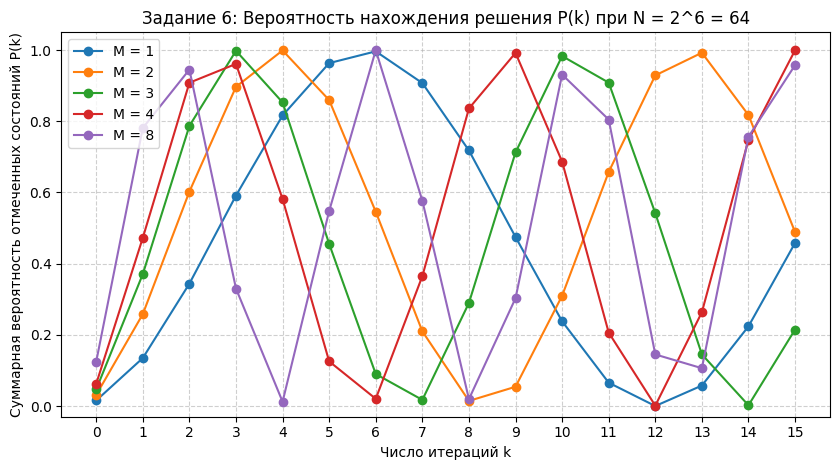

,Доля решений,M,Оптимальное k (0..7),P(k=0) (случайный выбор),Макс. P(k)
0,M = N/2,32,0,0.50,0.50
1,M = 3N/4,48,0,0.75,0.75


In [11]:
import math
import random
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

def build_multi_oracle(n: int, marked_list: list[str]) -> QuantumCircuit:
    """Оракул для набора отмеченных состояний как произведение фазовых инверсий U_{w_i}."""
    qc = QuantumCircuit(n, name="MultiOracle")
    for w in marked_list:
        qc.compose(build_oracle(n, w), inplace=True)
    return qc

def build_multi_grover(n: int, marked_list: list[str], k: int) -> QuantumCircuit:
    qc = QuantumCircuit(n)
    qc.h(range(n))
    oracle = build_multi_oracle(n, marked_list)
    diffuser = build_diffuser(n)
    for _ in range(k):
        qc.compose(oracle, inplace=True)
        qc.compose(diffuser, inplace=True)
    return qc

def first_local_maximum_idx(arr: np.ndarray) -> int:
    """Возвращает индекс первого локального максимума (или глобального, если монотонно растёт на [0..len-1])."""
    for i in range(1, len(arr) - 1):
        if arr[i] >= arr[i - 1] and arr[i] >= arr[i + 1]:
            return int(i)
    return int(np.argmax(arr))

n_6 = 6
N_6 = 2 ** n_6
all_states_6 = [f"{idx:0{n_6}b}" for idx in range(N_6)]
rng = random.Random(42)
ks_6 = np.arange(16)

# 1–2. M in {1, 2, 3, 4, 8}
m_values = [1, 2, 3, 4, 8]
table_rows = []
curves_6 = {}

for m in m_values:
    chosen = rng.sample(all_states_6, m)
    p_k = []
    for k in ks_6:
        sv = Statevector.from_instruction(build_multi_grover(n_6, chosen, int(k)))
        probs = sv.probabilities_dict()
        p_k.append(sum(float(probs.get(w, 0.0)) for w in chosen))
    p_k = np.array(p_k)
    curves_6[m] = p_k

    k_theor_m = math.floor((math.pi / 4.0) * math.sqrt(N_6 / m))
    k_first_max = first_local_maximum_idx(p_k)
    k_global_max = int(np.argmax(p_k))
    table_rows.append({
        "M": m,
        "k_теор": k_theor_m,
        "k_первый максимум": k_first_max,
        "P в 1-м максимуме": round(float(p_k[k_first_max]), 4),
        "k_глоб. макс. (0..15)": k_global_max,
    })

df_m = pd.DataFrame(table_rows)
display(df_m)

plt.figure(figsize=(8.5, 4.8))
for m in m_values:
    plt.plot(ks_6, curves_6[m], "o-", label=f"M = {m}")
plt.title(f"Задание 6: Вероятность нахождения решения P(k) при N = 2^{n_6} = {N_6}")
plt.xlabel("Число итераций k")
plt.ylabel("Суммарная вероятность отмеченных состояний P(k)")
plt.xticks(ks_6)
plt.ylim(-0.03, 1.05)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# 4. Проверка M = N/2 и M = 3N/4 при N = 2^6
dense_rows = []
for frac_label, m_dense in [("M = N/2", N_6 // 2), ("M = 3N/4", (3 * N_6) // 4)]:
    chosen_dense = rng.sample(all_states_6, m_dense)
    p_dense = []
    for k in range(8):
        sv = Statevector.from_instruction(build_multi_grover(n_6, chosen_dense, k))
        probs = sv.probabilities_dict()
        p_dense.append(sum(float(probs.get(w, 0.0)) for w in chosen_dense))
    p_dense = np.array(p_dense)
    best_k_dense = int(np.argmax(p_dense))
    dense_rows.append({
        "Доля решений": frac_label,
        "M": m_dense,
        "Оптимальное k (0..7)": best_k_dense,
        "P(k=0) (случайный выбор)": round(float(p_dense[0]), 4),
        "Макс. P(k)": round(float(np.max(p_dense)), 4),
    })

display(pd.DataFrame(dense_rows))

## Решение Задания 7 (7.1–7.3 — вариант 9; 7.4 — вариант 1)

,Вариант,N,|w>,k_теор,k_точн,k_эксп,max P_точн
0,9,2^5,|10110>,4,4,4,0.9992


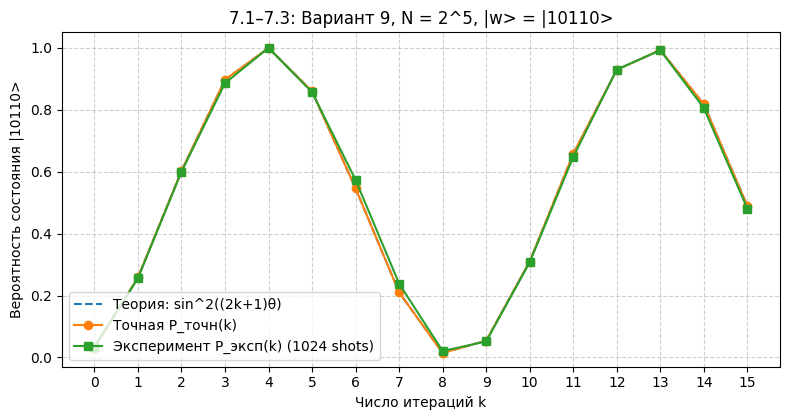

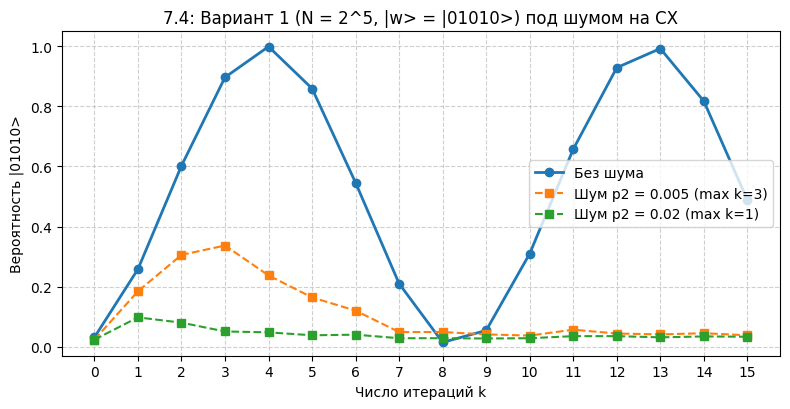

In [ ]:
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from qiskit import transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

#7.1–7.3. Вариант 9 (N = 2^5, |w> = |10110>), k = 0..15
var_id = 9
n_bits = 5
N_val = 2 ** n_bits
marked_str = "10110"
ks = np.arange(16)
shots = 1024
sim = AerSimulator()

p_exact = np.array([
    float(Statevector.from_instruction(build_grover(n_bits, marked_str, int(k), measure=False)).probabilities_dict().get(marked_str, 0.0))
    for k in ks
])

meas_qcs = [build_grover(n_bits, marked_str, int(k), measure=True) for k in ks]
counts_list = sim.run(transpile(meas_qcs, sim), shots=shots).result().get_counts()
p_exp = np.array([c.get(marked_str, 0) / shots for c in counts_list])

theta = math.asin(1.0 / math.sqrt(N_val))
p_theory = np.sin((2 * ks + 1) * theta) ** 2

k_theor = math.floor((math.pi / 4.0) * math.sqrt(N_val))
k_точн = first_local_maximum_idx(p_exact)
k_эксп = int(np.argmax(p_exp))
max_p_точн = float(np.max(p_exact))

df_var9 = pd.DataFrame([{
    "Вариант": var_id,
    "N": f"2^{n_bits}",
    "|w>": f"|{marked_str}>",
    "k_теор": k_theor,
    "k_точн": k_точн,
    "k_эксп": k_эксп,
    "max P_точн": round(max_p_точн, 4),
}])
display(df_var9)

plt.figure(figsize=(8, 4.3))
plt.plot(ks, p_theory, "--", label="Теория: sin^2((2k+1)θ)")
plt.plot(ks, p_exact, "o-", label="Точная P_точн(k)")
plt.plot(ks, p_exp, "s-", label=f"Эксперимент P_эксп(k) ({shots} shots)")
plt.title(f"7.1–7.3: Вариант {var_id}, N = 2^{n_bits}, |w> = |{marked_str}>")
plt.xlabel("Число итераций k")
plt.ylabel(f"Вероятность состояния |{marked_str}>")
plt.xticks(ks)
plt.ylim(-0.03, 1.05)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# 7.4. Вариант 1 (N = 2^5, |w> = |01010>), шум p2 = 0.005 и p2 = 0.02
v1_n = 5
v1_marked = "01010"

p_id_1 = np.array([
    float(Statevector.from_instruction(build_grover(v1_n, v1_marked, int(k), measure=False)).probabilities_dict().get(v1_marked, 0.0))
    for k in ks
])
raw_qcs_1 = [build_grover(v1_n, v1_marked, int(k), measure=True) for k in ks]

plt.figure(figsize=(8, 4.2))
plt.plot(ks, p_id_1, "o-", linewidth=2, label="Без шума")

for p2_val in (0.005, 0.02):
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(depolarizing_error(0.001, 1), ["x", "sx", "rz", "h", "id"])
    nm.add_all_qubit_quantum_error(depolarizing_error(p2_val, 2), ["cx"])
    n_sim = AerSimulator(noise_model=nm)
    cnts = n_sim.run(transpile(raw_qcs_1, n_sim), shots=1024, seed_simulator=123).result().get_counts()
    p_n = np.array([c.get(v1_marked, 0) / 1024 for c in cnts])
    plt.plot(ks, p_n, "s--", label=f"Шум p2 = {p2_val} (max k={int(ks[np.argmax(p_n)])})")

plt.title(f"7.4: Вариант 1 (N = 2^5, |w> = |{v1_marked}>) под шумом на CX")
plt.xlabel("Число итераций k")
plt.ylabel(f"Вероятность |{v1_marked}>")
plt.xticks(ks)
plt.ylim(-0.03, 1.05)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()